# AstraFlame: full data-science and machine-learning pipeline

**Team Agnishikha · NASA Space Apps Challenge 2026 · Challenge: *Flame in Freefall***
**Data Science Lead: Prachya Biswas**

This notebook runs the whole data-science part of AstraFlame from NASA's data to the final models, in one place:

| Section | What it shows |
|---|---|
| 0 | Setup (finds the repository, checks library versions) |
| 1 | The five prediction tasks and the NASA data behind them |
| 2 | Data quality: reproducible ETL and the data contract |
| 3 | Preprocessing: every step and why |
| 4 | Train / validation / test design, and why a random split would cheat |
| 5 | Noise ceiling: the best score any model could reach on this data |
| 6 | Model comparison on identical held-out tests (R², MAE, coverage, AUC, Brier, accuracy, F1, confusion matrix) |
| 7 | Improvements tried after mentor feedback, with honest results |
| 8 | Physics consistency check |
| 9 | Final models in use: predictions with a 90% range, warnings and explanations |
| 10 | Final results and limits |

**How to run on a laptop**

```
git clone https://github.com/prachyabiswas/NASA-Space-Apps-2026.git
cd NASA-Space-Apps-2026
pip install -r requirements.txt jupyter
jupyter notebook notebooks/AstraFlame_Full_ML_Pipeline.ipynb      # then: Kernel -> Restart & Run All
```

Run time is about 10–15 minutes on a laptop. The inner-loop tuning of the classical model families (nested cross-validation, about 50 minutes) is loaded from its saved result by default; set `RUN_FULL_NESTED_CV = True` in the setup cell to recompute it.

## 0. Setup

In [1]:
import os, sys, json, time, subprocess, warnings
from pathlib import Path

RUN_FULL_NESTED_CV = False   # True = re-tune all classical families from scratch (about 50 min)
SEED = 42
warnings.filterwarnings("ignore")

def find_repo():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "run_pipeline.py").exists() and (p / "models").exists():
            return p
    if "google.colab" in sys.modules:              # Colab: fetch the repository
        subprocess.run(["git", "clone", "-q", "https://github.com/prachyabiswas/NASA-Space-Apps-2026.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "NASA-Space-Apps-2026/requirements.txt"], check=True)
        return Path("NASA-Space-Apps-2026").resolve()
    raise FileNotFoundError("Open this notebook from inside the NASA-Space-Apps-2026 repository.")

ROOT = find_repo()
sys.path.insert(0, str(ROOT / "models"))

import numpy as np, pandas as pd, joblib, sklearn, scipy, matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.model_selection import KFold, GroupKFold
from sklearn.linear_model import Ridge
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, roc_auc_score, roc_curve, brier_score_loss,
                             log_loss, accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix)

import config as C
import preprocess_v3 as P
from pigp import PhysicsGPRegressor, PhysicsGPClassifier
from ml_selection import make_cv, checked_splits, LeakageError, group_bootstrap_ci
import ignis_models as IM

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
np.random.seed(SEED)
print("repository:", ROOT)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
assert sklearn.__version__ == "1.9.1", "the saved model files need scikit-learn 1.9.1 (pip install -r requirements.txt)"

repository: /home/claude/nasa-space-apps-2026
python 3.13.16 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | scipy 1.18.1


## 1. The five prediction tasks

Each task answers one fire-safety question with data NASA measured in microgravity. A *group* is one independent ISS test (or test series, or run); rows from the same group share hardware and conditions, so they are never split between training and testing.

In [2]:
S = P.all_specs()          # loads data/processed and applies the preprocessing of section 3
QUESTION = {
    "bass2_flame_spread": ("How fast does a flame spread over a solid (PMMA rod)?", "BASS-II, PSI-25"),
    "flex_extinction":    ("Will a burning fuel droplet's flame go out before the fuel is used up?", "FLEX, PSI-69"),
    "flex_burning_rate":  ("How fast does a fuel droplet burn?", "FLEX, PSI-69"),
    "spice_smoke_point":  ("How sooty / smoky is a gas flame (smoke-point length)?", "SPICE, PSI-107"),
    "same_particle_size": ("How large are the smoke particles a detector must see?", "SAME / SAME-R, PSI-101/102"),
}
summary = pd.DataFrame([{
    "task": n, "question": QUESTION[n][0], "NASA source": QUESTION[n][1], "type": s["task"],
    "rows": len(s["y"]), "independent groups": len(np.unique(s["g"])), "features": s["X"].shape[1]}
    for n, s in S.items()])
display(summary)

,task,question,NASA source,type,rows,independent groups,features
0,bass2_flame_spread,How fast does a flame spread over a solid (PMMA rod)?,"BASS-II, PSI-25",regression,52,19,6
1,flex_extinction,Will a burning fuel droplet's flame go out before the fuel is used up?,"FLEX, PSI-69",classification,206,65,7
2,flex_burning_rate,How fast does a fuel droplet burn?,"FLEX, PSI-69",regression,256,78,7
3,spice_smoke_point,How sooty / smoky is a gas flame (smoke-point length)?,"SPICE, PSI-107",regression,55,11,6
4,same_particle_size,How large are the smoke particles a detector must see?,"SAME / SAME-R, PSI-101/102",regression,125,78,8


## 2. Data quality

`build_all.py --check` rebuilds every processed file from the verbatim NASA extracts and proves the result is byte-for-byte identical (890 value checks against NASA, including all 52 ground-test rows checked against Hirsch et al. 2011). `validate_processed.py` runs the data contract: schema, keys, row counts, categories, physics bounds, cross-field consistency and lineage.

In [3]:
for script, args in [("build_all.py", ["--check"]), ("validate_processed.py", [])]:
    r = subprocess.run([sys.executable, str(ROOT / "data" / "scripts" / script), *args], cwd=ROOT, capture_output=True, text=True)
    print(f"$ python data/scripts/{script} {' '.join(args)}  -> exit code {r.returncode}")
    print("\n".join(r.stdout.strip().splitlines()[-3:]), "\n")

$ python data/scripts/build_all.py --check  -> exit code 0
checks run: 890; problems: 0
reproducible: all 9 files rebuilt byte-for-byte from the NASA extracts 

$ python data/scripts/validate_processed.py   -> exit code 0
data contract: 130 passed, 0 warnings, 0 errors 



## 3. Preprocessing: every step and why

The preprocessing is designed for the chosen model (a physics-informed Gaussian process, section 6): inputs are put in the form the physics laws use (logarithms, oxygen partial pressure, 1/diameter), rows whose outcome is undefined are removed with the reason logged, and each row keeps the id of the ISS test it came from.

In [4]:
log_rows = [{"task": t, "step": s["step"], "why": s["why"], "rows after": s["rows_after"]} for t, steps in P.LOG.items() for s in steps]
with pd.option_context("display.max_colwidth", 110):
    display(pd.DataFrame(log_rows))
print("\nFeatures after preprocessing (FLEX extinction, first 5 rows):")
display(S["flex_extinction"]["X"].head())
print("Target-leak check: no feature is a copy of the target, every row has a group id -> passed for all 5 tasks")

,task,step,why,rows after
0,bass2_flame_spread,load NASA PSI-25 / Link et al. 2018 Table S1,verified extract of measured spread rates,52
1,bass2_flame_spread,"keep flow steps as separate rows, group = ISS test",flow changes within a test; rows of one test share hardware and are not independent,52
2,bass2_flame_spread,"physics space: log O2, log(1/diameter), log flow + flow; target log(spread)","spread follows power laws in O2 and rod size (thin-rod spread ~ 1/d); in microgravity spread first rises with opposed flow (more O2 delivered) then falls (flame cooled/blown off), so flow enters as u^a * exp(b*u)",52
3,bass2_flame_spread,noise prior from 39 near-replicate pairs (log scale),the GP starts from measured run-to-run noise instead of guessing it,52
4,flex_extinction,load NASA PSI-69 FLEX table,274 ISS droplet tests,274
5,flex_extinction,drop 68 tests: 61 'Disruption' (no clean outcome) + 7 with droplet size or pressure missing in the NASA file,a droplet that broke up has neither extinguished nor burned out: its label is undefined,206
6,flex_extinction,"physics features: O2 partial pressure, log pressure, diluent %, droplet size, fuel","extinction depends on how much O2 reaches the flame (partial pressure), heat loss (size, diluent) and fuel",206
7,flex_extinction,group = FLEX test series (first 3 characters of the FLEX id),a series shares the same chamber fill; whole series are held out,206
8,flex_burning_rate,load NASA PSI-69 FLEX table,274 ISS droplet tests,274
9,flex_burning_rate,"drop 16 tests without K, 1 with K <= 0.1 and those missing size or pressure",K is the slope of the d^2-law; it must be measured and physical,256



Features after preprocessing (FLEX extinction, first 5 rows):


,is_heptane,log_p,o2_pct,o2_partial_kpa,co2_pct,he_pct,d0_mm
0,0.0,4.621044,21.0,21.336,0.0,0.0,1.86
1,0.0,4.623992,21.0,21.399,0.0,0.0,1.61
2,0.0,4.618086,21.0,21.273,0.0,0.0,2.06
3,0.0,4.618086,21.0,21.273,0.0,0.0,1.92
4,0.0,4.618086,21.0,21.273,0.0,0.0,2.54


Target-leak check: no feature is a copy of the target, every row has a group id -> passed for all 5 tasks


## 4. Train / validation / test design

The data are small (52 to 256 rows per task), so one fixed 70/30 split would give a score that depends on luck. Every score in this notebook comes from **grouped cross-validation**:

* **Test** = the outer folds. A whole ISS test, series or run is held out, and the model is scored only on groups it never saw. Repeated 3 times with different fold assignments (leave-one-group-out when there are few groups).
* **Validation** = the inner folds, inside each outer training set only, used to choose models, hyper-parameters, the GP correction and the decision threshold.
* **Train** = the remaining rows of each fold.

Why groups matter: rows from the same ISS test are near-copies. If they land on both sides of a random split, the model is tested on data it has effectively seen. The demonstration below scores the same model both ways.

In [5]:
sp = S["bass2_flame_spread"]; X, y, g = sp["X"], sp["y"], sp["g"]
def cv_r2(splitter, reps=5):
    out = []
    for r in range(reps):
        p = np.zeros(len(y))
        folds = splitter(r)
        for tr, te in folds:
            m = Ridge(alpha=1.0).fit(X.iloc[tr], np.log(y[tr])); p[te] = np.exp(m.predict(X.iloc[te]))
        out.append(r2_score(y, p))
    return np.mean(out)
random_r2  = cv_r2(lambda r: KFold(5, shuffle=True, random_state=r).split(X))
grouped_r2 = cv_r2(lambda r: GroupKFold(5, shuffle=True, random_state=r).split(X, y, g))
print(f"Same model, BASS-II flame spread:  random split R2 = {random_r2:.3f}   |   grouped split R2 = {grouped_r2:.3f}")
print(f"A random split would overstate the score by {random_r2 - grouped_r2:+.3f}.")
try:
    checked_splits(KFold(5, shuffle=True, random_state=0), X, y, g, "demo")
except LeakageError as e:
    print("Leakage guard (used for every split in this project) refuses the random split:", str(e)[:110], "...")

Same model, BASS-II flame spread:  random split R2 = 0.588   |   grouped split R2 = 0.560
A random split would overstate the score by +0.028.
Leakage guard (used for every split in this project) refuses the random split: group leakage demo fold 0: ['P13a', 'P13b', 'P16', 'P19', 'P3a'] in both train and test ...


## 5. Noise ceiling: how good can any model be?

NASA sometimes ran different tests at (almost) the same conditions. Their results still differ because of measurement and run-to-run noise, which no model can predict. From those near-replicate pairs: noise variance ≈ mean((yᵢ − yⱼ)²)/2, and the **best possible R²** ≈ 1 − noise variance / total variance. A model close to this ceiling cannot be improved much by better modelling, only by more or cleaner experiments.

In [6]:
def ceiling(Xc, yc, gc, tol, log=False):
    yc = np.log(yc) if log else np.asarray(yc, float)
    Z = ((Xc - Xc.mean()) / Xc.std(ddof=0).replace(0, 1)).values; d2 = []
    for i in range(len(Z)):
        for j in range(i + 1, len(Z)):
            if gc[i] != gc[j] and np.sqrt(((Z[i] - Z[j]) ** 2).sum()) <= tol:
                d2.append((yc[i] - yc[j]) ** 2)
    noise = np.mean(d2) / 2
    return {"near-replicate pairs": len(d2), "max R2 possible": 1 - noise / yc.var()}

D = C.DATA_DIR
d = pd.read_csv(D / "BASS-II_flame_spread_microgravity_v1.0.csv")
x = pd.read_csv(D / "FLEX_PSI-69_clean_v1.0.csv"); x["co2_pct"] = x.x_CO2 * 100; x["he_pct"] = x.x_He * 100
k = x[x.burning_rate_K_mm2_s.notna() & x.d0_mm.notna() & x.pressure_kpa.notna() & (x.burning_rate_K_mm2_s > 0.1)].reset_index(drop=True)
s = pd.read_csv(D / "SPICE_PSI-107_smoke_points_v1.0.csv")
m0 = pd.read_csv(D / "SAME_PSI-101-102_smoke_particles_v1.0.csv")
m0 = m0[m0.use_for_particle_size_model & m0.sample_temperature_c.notna() & m0.net_aging_time_s.notna()].reset_index(drop=True)
raw = pd.DataFrame({"material": m0.material, "sample_temperature_c": m0.sample_temperature_c, "air_velocity_cm_s": m0.inlet_air_velocity_cm_s,
                    "aging_time_s": m0.net_aging_time_s, "campaign": np.where(m0.psi_id == "PSI-102", "SAME", "SAME-R")})
CEIL = {
    "bass2_flame_spread": ceiling(IM.bass2_features(d), d.flame_spread_mm_s.values, d.test_id.values, 0.35),
    "flex_burning_rate":  ceiling(IM.flex2_features(k), k.burning_rate_K_mm2_s.values, k.flex_id.str[:3].values, 0.25),
    "spice_smoke_point":  ceiling(IM.spice_features(s), s.smoke_point_length_mm.values, s.gmt_day_2009.values, 0.25),
    "same_particle_size": ceiling(IM.same2_features(raw), m0.count_mean_diameter_um.values, (m0.campaign.str[:6] + m0.same_run.str.rstrip("a")).values, 0.35),
}
display(pd.DataFrame(CEIL).T.round(3))

,near-replicate pairs,max R2 possible
bass2_flame_spread,32.0,0.678
flex_burning_rate,27.0,0.722
spice_smoke_point,16.0,0.995
same_particle_size,156.0,0.843


## 6. Model comparison on identical held-out tests

Candidates for every task, all scored on **the same outer folds**:

* **PI-GP (proposed)**: physics-informed Gaussian process = a physics law (fitted by ridge regression) + a Gaussian-process correction + an ISS-test offset. The correction is kept only if inner validation shows it helps. It gives its own 90% prediction range, and far from the data it falls back to the physics law.
* **Physics law only**: the PI-GP's physics part alone.
* **Classical families**, each tuned in the inner loop (8 for regression, 7 for classification): ridge or logistic regression, the same with pairwise interactions, k-nearest neighbours, SVM/SVR, Gaussian process (ARD, regression only), random forest, extra trees, gradient boosting; plus the **v2 ensemble** (average of the 3 best, with a physics-form fallback outside the tested range).
* **Baselines**: the mean of the training folds (regression) or always predicting the most common class (classification).

The final model per task is chosen from the project's objective, before looking at the scores: the three outputs that feed the safe-cabin map (flame spread, extinction, burning rate) need physics-consistent answers with a calibrated range, so they use the PI-GP; the two smoke outputs are read inside the tested range, so the most accurate model is used.

In [7]:
NEST = joblib.load(C.artifact("v2_nested_cache.joblib"))       # inner-loop tuning of the 8 families (train_v2.py)
if RUN_FULL_NESTED_CV:
    subprocess.run([sys.executable, "train_v2.py"], cwd=ROOT / "models", check=True)
    NEST = joblib.load(C.artifact("v2_nested_cache.joblib"))
OUTER = {"bass2_flame_spread": "logo", "flex_extinction": "kfold", "flex_burning_rate": "kfold",
         "spice_smoke_point": "logo", "same_particle_size": "kfold"}
FINAL = {"bass2_flame_spread": "PI-GP (proposed)", "flex_extinction": "PI-GP (proposed)", "flex_burning_rate": "PI-GP (proposed)",
         "spice_smoke_point": "v2 ensemble (top-3 average + fallback)", "same_particle_size": "v2 ensemble (top-3 average + fallback)"}

def outer_splits(name):
    sp = S[name]; reps = NEST[name]["res"]["reps"]
    return [checked_splits(make_cv(OUTER[name], len(np.unique(sp["g"])), seed=r), sp["X"], sp["y"], sp["g"], f"{name} repeat {r}")
            for r in range(reps)]

PRED = {}       # task -> candidate -> array (repeats x rows) of held-out predictions
BAND = {}       # task -> (lo, hi) held-out 90% ranges of the PI-GP
t0 = time.time()
for name, sp in S.items():
    X, y, g = sp["X"], sp["y"], sp["g"]; R = outer_splits(name); cls = sp["task"] == "classification"
    P1 = np.zeros((len(R), len(y))); PH = np.zeros_like(P1); BASE = np.zeros_like(P1); LO = np.zeros_like(P1); HI = np.zeros_like(P1)
    for r, folds in enumerate(R):
        for tr, te in folds:
            if cls:
                m = PhysicsGPClassifier(gp_cols=sp["gp_cols"]).fit(X.iloc[tr], y[tr]); P1[r, te] = m.predict_proba(X.iloc[te])[:, 1]
                BASE[r, te] = y[tr].mean()
            else:
                m = PhysicsGPRegressor(mean_cols=sp["mean_cols"], gp_cols=sp["gp_cols"], log_target=sp["log_target"],
                                       noise=sp["noise"]).fit(X.iloc[tr], y[tr], groups=g[tr])
                P1[r, te] = m.predict(X.iloc[te]); LO[r, te], HI[r, te] = m.predict_interval(X.iloc[te]); PH[r, te] = m.physics_only(X.iloc[te])
                BASE[r, te] = y[tr].mean()
    res = NEST[name]["res"]
    PRED[name] = {"PI-GP (proposed)": P1}
    if not cls:
        PRED[name]["Physics law only"] = PH; BAND[name] = (LO, HI)
    PRED[name]["v2 ensemble (top-3 average + fallback)"] = res["proc_pred"]["top-3 average + physics-form fallback outside tested domain"]
    for f, M in res["fam_pred"].items():
        PRED[name][f + " (tuned)"] = M
    PRED[name]["Baseline (training mean / base rate)"] = BASE
    print(f"{name}: held-out predictions ready ({time.time() - t0:.0f}s)")

bass2_flame_spread: held-out predictions ready (16s)
flex_extinction: held-out predictions ready (34s)
flex_burning_rate: held-out predictions ready (176s)
spice_smoke_point: held-out predictions ready (211s)
same_particle_size: held-out predictions ready (263s)


### 6a. Regression tasks: R², MAE, RMSE, 90% coverage, and how close each model gets to the noise ceiling

In [8]:
def fixed_band(y, p, folds, log):
    lo, hi = np.zeros(len(y)), np.zeros(len(y))
    err = np.log(np.maximum(p / y, y / p)) if log else np.abs(y - p)
    for tr, te in folds:
        q = np.quantile(err[tr], 0.9)
        lo[te], hi[te] = (p[te] * np.exp(-q), p[te] * np.exp(q)) if log else (p[te] - q, p[te] + q)
    return lo, hi

REG = {}
for name, sp in S.items():
    if sp["task"] != "regression": continue
    y = sp["y"]; R = outer_splits(name); rows = []
    for cand, M in PRED[name].items():
        ms = []
        for r, folds in enumerate(R):
            p = M[r]
            lo, hi = (BAND[name][0][r], BAND[name][1][r]) if cand == "PI-GP (proposed)" else fixed_band(y, np.maximum(p, 1e-9), folds, sp["log_target"])
            ms.append({"R2": r2_score(y, p), "MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5,
                       "90% coverage": 100 * np.mean((y >= lo) & (y <= hi))})
        row = {"model": cand} | pd.DataFrame(ms).mean().to_dict()
        row["% of max possible R2"] = 100 * row["R2"] / CEIL[name]["max R2 possible"]
        row["final"] = "<- final" if cand == FINAL[name] else ""
        rows.append(row)
    REG[name] = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
    print(f"\n=== {name}   (max R2 possible = {CEIL[name]['max R2 possible']:.3f})")
    display(REG[name].round(3))


=== bass2_flame_spread   (max R2 possible = 0.678)


,model,R2,MAE,RMSE,90% coverage,% of max possible R2,final
0,Ridge (linear) (tuned),0.620,0.009,0.012,86.538,91.480,
1,v2 ensemble (top-3 average + fallback),0.616,0.009,0.012,88.462,90.798,
2,Physics law only,0.578,0.010,0.012,86.538,85.280,
3,PI-GP (proposed),0.568,0.010,0.012,86.538,83.741,<- final
4,Support vector regression (RBF) (tuned),0.529,0.010,0.013,88.462,78.042,
5,Extra trees (tuned),0.500,0.009,0.013,86.538,73.733,
6,k-nearest neighbours (tuned),0.423,0.012,0.014,88.462,62.334,
7,Ridge + pairwise interactions (tuned),0.392,0.011,0.015,86.538,57.872,
8,Gradient boosting (tuned),0.370,0.011,0.015,86.538,54.533,
9,Random forest (tuned),0.324,0.012,0.016,88.462,47.757,



=== flex_burning_rate   (max R2 possible = 0.722)


,model,R2,MAE,RMSE,90% coverage,% of max possible R2,final
0,v2 ensemble (top-3 average + fallback),0.712,0.045,0.072,89.974,98.694,
1,PI-GP (proposed),0.706,0.047,0.073,89.714,97.861,<- final
2,Ridge (linear) (tuned),0.697,0.048,0.074,89.844,96.583,
3,Support vector regression (RBF) (tuned),0.693,0.045,0.075,89.583,95.978,
4,Physics law only,0.689,0.049,0.075,89.583,95.420,
5,Gaussian process (ARD) (tuned),0.686,0.048,0.075,89.193,95.030,
6,Gradient boosting (tuned),0.641,0.055,0.081,89.714,88.857,
7,Extra trees (tuned),0.629,0.052,0.082,89.453,87.236,
8,k-nearest neighbours (tuned),0.621,0.058,0.083,89.583,86.006,
9,Random forest (tuned),0.595,0.056,0.085,89.453,82.476,



=== spice_smoke_point   (max R2 possible = 0.995)


,model,R2,MAE,RMSE,90% coverage,% of max possible R2,final
0,v2 ensemble (top-3 average + fallback),0.886,4.394,7.314,87.273,89.046,<- final
1,Ridge (linear) (tuned),0.850,5.667,8.378,90.909,85.454,
2,Physics law only,0.849,5.683,8.415,89.091,85.321,
3,PI-GP (proposed),0.787,6.249,9.971,78.182,79.165,
4,Gradient boosting (tuned),0.592,6.613,13.802,89.091,59.573,
5,Support vector regression (RBF) (tuned),0.579,6.320,14.031,90.909,58.202,
6,Gaussian process (ARD) (tuned),0.558,6.924,14.379,89.091,56.079,
7,Ridge + pairwise interactions (tuned),0.469,8.315,15.752,87.273,47.179,
8,Random forest (tuned),0.462,8.365,15.863,90.909,46.420,
9,k-nearest neighbours (tuned),0.426,8.368,16.374,87.273,42.878,



=== same_particle_size   (max R2 possible = 0.843)


,model,R2,MAE,RMSE,90% coverage,% of max possible R2,final
0,Random forest (tuned),0.447,0.061,0.111,89.600,53.011,
1,v2 ensemble (top-3 average + fallback),0.429,0.063,0.113,89.067,50.857,<- final
2,Extra trees (tuned),0.400,0.066,0.116,89.867,47.474,
3,Support vector regression (RBF) (tuned),0.396,0.066,0.116,89.600,47.011,
4,k-nearest neighbours (tuned),0.390,0.066,0.117,88.533,46.249,
5,Gaussian process (ARD) (tuned),0.385,0.070,0.117,88.800,45.662,
6,Gradient boosting (tuned),0.356,0.072,0.120,89.067,42.236,
7,Physics law only,0.319,0.070,0.123,89.600,37.882,
8,PI-GP (proposed),0.316,0.068,0.124,89.600,37.545,
9,Ridge (linear) (tuned),0.301,0.071,0.125,89.333,35.769,


### 6b. Classification task (FLEX extinction): every metric

87% of the 206 ISS droplet tests ended with the flame going out, so **accuracy alone is misleading**: always answering "goes out" already scores 0.869. The metrics that matter here are ROC-AUC (ranking), Brier score (probability quality, lower is better), balanced accuracy and macro-F1 (both classes count equally) and the F1 of the rare class ("burns to completion").

In [9]:
sp = S["flex_extinction"]; y = sp["y"]; R = outer_splits("flex_extinction")

def clf_row(cand, p_rep, thr=0.5):
    ms = []
    for p in p_rep:
        pc = np.clip(p, 1e-4, 1 - 1e-4); yh = (pc >= thr).astype(int)
        constant = cand.startswith("Baseline")      # a constant guess cannot rank tests: AUC is 0.5 by definition
        ms.append({"ROC-AUC": 0.5 if constant else roc_auc_score(y, pc), "Brier": brier_score_loss(y, pc), "log loss": log_loss(y, pc),
                   "accuracy": accuracy_score(y, yh), "balanced accuracy": balanced_accuracy_score(y, yh),
                   "macro F1": f1_score(y, yh, average="macro"), "F1 goes out": f1_score(y, yh),
                   "F1 burns to completion": f1_score(1 - y, 1 - yh, zero_division=0)})
    return {"model": cand} | pd.DataFrame(ms).mean().to_dict()

CLF = pd.DataFrame([clf_row(c, M) for c, M in PRED["flex_extinction"].items()]).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
CLF["final"] = np.where(CLF.model == FINAL["flex_extinction"], "<- final", "")
print("All candidates at the default threshold 0.5 (held-out, mean of 3 repeats):")
display(CLF.round(3))

All candidates at the default threshold 0.5 (held-out, mean of 3 repeats):


,model,ROC-AUC,Brier,log loss,accuracy,balanced accuracy,macro F1,F1 goes out,F1 burns to completion,final
0,PI-GP (proposed),0.867,0.082,0.271,0.879,0.652,0.680,0.932,0.427,<- final
1,Logistic + pairwise interactions (tuned),0.834,0.089,0.303,0.887,0.589,0.615,0.938,0.292,
2,v2 ensemble (top-3 average + fallback),0.833,0.090,0.299,0.877,0.589,0.614,0.933,0.295,
3,k-nearest neighbours (tuned),0.829,0.096,0.308,0.869,0.531,0.529,0.929,0.128,
4,Extra trees (tuned),0.813,0.097,0.316,0.869,0.558,0.571,0.929,0.213,
5,Logistic regression (tuned),0.803,0.088,0.316,0.887,0.594,0.625,0.938,0.311,
6,Support vector machine (RBF) (tuned),0.779,0.096,0.330,0.874,0.587,0.609,0.931,0.288,
7,Random forest (tuned),0.751,0.102,0.347,0.866,0.530,0.526,0.927,0.124,
8,Gradient boosting (tuned),0.695,0.107,0.366,0.867,0.567,0.584,0.927,0.240,
9,Baseline (training mean / base rate),0.500,0.116,0.397,0.869,0.500,0.465,0.930,0.000,


### 6c. Decision threshold chosen on validation folds only

A probability becomes a yes/no answer at a threshold. Using 0.5 with an 87/13 class balance almost never predicts "burns to completion". Here the threshold is **chosen inside each training set** (inner grouped folds, maximising balanced accuracy) and then applied to the untouched test fold, so the test data never influence it.

,decision rule,accuracy,balanced accuracy,macro F1,precision burns-out,recall burns-out,F1 burns to completion,F1 goes out
0,"PI-GP, threshold 0.5",0.879,0.652,0.680,0.560,0.346,0.427,0.932
1,"PI-GP, threshold chosen on validation folds",0.820,0.776,0.701,0.404,0.716,0.512,0.889
2,Always 'goes out' (baseline),0.869,0.500,0.465,0.000,0.000,0.000,0.930


Thresholds chosen on the 15 validation sets: median 0.78 (range 0.49-0.89)


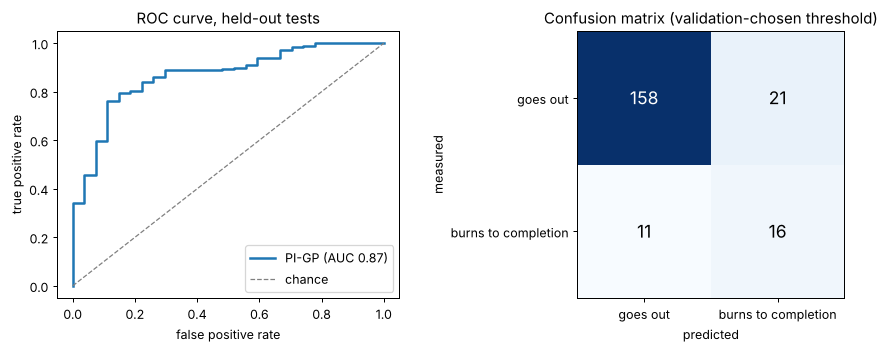

In [10]:
def inner_threshold(Xtr, ytr, gtr):
    oof = np.zeros(len(ytr))
    for tr, te in make_cv("kfold", len(np.unique(gtr)), seed=11).split(Xtr, ytr, gtr):
        oof[te] = PhysicsGPClassifier(gp_cols=sp["gp_cols"]).fit(Xtr.iloc[tr], ytr[tr]).predict_proba(Xtr.iloc[te])[:, 1]
    ts = np.linspace(0.30, 0.97, 68)
    return ts[np.argmax([balanced_accuracy_score(ytr, (oof >= t).astype(int)) for t in ts])]

X, g = sp["X"], sp["g"]; P_GP = PRED["flex_extinction"]["PI-GP (proposed)"]
YH_T = np.zeros_like(P_GP); THR = []
for r, folds in enumerate(R):
    for tr, te in folds:
        t = inner_threshold(X.iloc[tr], y[tr], g[tr]); THR.append(t)
        YH_T[r, te] = (P_GP[r, te] >= t)
rows = []
for label, YH in [("PI-GP, threshold 0.5", (P_GP >= 0.5).astype(int)), ("PI-GP, threshold chosen on validation folds", YH_T.astype(int)),
                  ("Always 'goes out' (baseline)", np.ones_like(P_GP, dtype=int))]:
    ms = [{"accuracy": accuracy_score(y, yh), "balanced accuracy": balanced_accuracy_score(y, yh), "macro F1": f1_score(y, yh, average="macro"),
           "precision burns-out": precision_score(1 - y, 1 - yh, zero_division=0), "recall burns-out": recall_score(1 - y, 1 - yh, zero_division=0),
           "F1 burns to completion": f1_score(1 - y, 1 - yh, zero_division=0), "F1 goes out": f1_score(y, yh)} for yh in YH]
    rows.append({"decision rule": label} | pd.DataFrame(ms).mean().to_dict())
THRESH = pd.DataFrame(rows)
display(THRESH.round(3))
print(f"Thresholds chosen on the 15 validation sets: median {np.median(THR):.2f} (range {min(THR):.2f}-{max(THR):.2f})")

cm = confusion_matrix(y, YH_T[0].astype(int), labels=[1, 0])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y, P_GP[0]); ax[0].plot(fpr, tpr, lw=2, label=f"PI-GP (AUC {roc_auc_score(y, P_GP[0]):.2f})")
ax[0].plot([0, 1], [0, 1], "--", color="grey", lw=1, label="chance"); ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate")
ax[0].set_title("ROC curve, held-out tests"); ax[0].legend(loc="lower right")
ax[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[1].set_xticks([0, 1], ["goes out", "burns to completion"]); ax[1].set_yticks([0, 1], ["goes out", "burns to completion"])
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("measured"); ax[1].set_title("Confusion matrix (validation-chosen threshold)")
plt.tight_layout(); plt.show()

### 6d. Predicted vs measured (final models, held-out tests)

Each plot shows the first of the three repeats, so its R² can differ slightly from the 3-repeat mean in the tables.

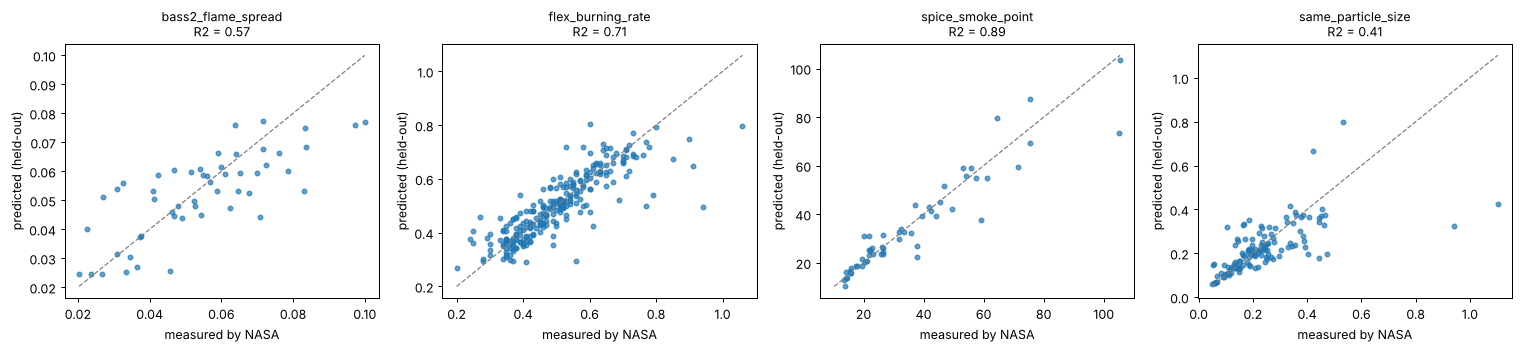

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, name in zip(axes, [n for n in S if S[n]["task"] == "regression"]):
    y = S[name]["y"]; p = PRED[name][FINAL[name]][0]
    ax.scatter(y, p, s=14, alpha=0.7)
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]; ax.plot(lim, lim, "--", color="grey", lw=1)
    ax.set_title(f"{name}\nR2 = {r2_score(y, p):.2f}", fontsize=10); ax.set_xlabel("measured by NASA"); ax.set_ylabel("predicted (held-out)")
plt.tight_layout(); plt.show()

## 7. Improvements tried after mentor feedback

**7a. Extinction model (rare class).** Done in 6c: choosing the decision threshold on validation folds raises balanced accuracy and the F1 of the rare class, while the probabilities (AUC, Brier) stay the same. This rule is the recommended way to turn the model's probability into a yes/no answer.

**7b. Smoke particle size (SAME).** This task reaches only about half of its noise ceiling, so three feature sets were tried with five model types, all on the same grouped folds: the current features; plus temperature relative to each material's tested range; plus material × temperature interactions and a fresh/aged flag. The target is log(diameter).

In [12]:
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as CK
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeCV

sp = S["same_particle_size"]; rawS, yS, gS = sp["raw"], sp["y"], sp["g"]; lyS = np.log(yS)
def same_feats(kind):
    Xf = P.same_features(rawS).copy()
    if kind != "current features":
        lo = rawS.groupby("material").sample_temperature_c.transform("min"); hi = rawS.groupby("material").sample_temperature_c.transform("max")
        Xf["temp_rel"] = (rawS.sample_temperature_c - lo) / (hi - lo).replace(0, 1)
    if kind == "+ relative temperature + interactions":
        for mt in P.SAME_MATERIALS[1:]:
            Xf[f"T_x_{mt}"] = Xf[f"mat_{mt}"] * Xf["temp_rel"]
        Xf["aged"] = (rawS.aging_time_s > 30).astype(float)
    return Xf
def same_cv(fn, Xf):
    out = []
    for r in range(3):
        p = np.zeros(len(yS))
        for tr, te in checked_splits(make_cv("kfold", len(np.unique(gS)), seed=r), Xf, lyS, gS, "same"):
            p[te] = fn(Xf.shape[1]).fit(Xf.iloc[tr], lyS[tr]).predict(Xf.iloc[te])
        out.append(r2_score(yS, np.exp(p)))
    return np.mean(out)
FAM = {"Random forest": lambda n: RandomForestRegressor(500, min_samples_leaf=2, random_state=0, n_jobs=-1),
       "Extra trees": lambda n: ExtraTreesRegressor(500, min_samples_leaf=2, random_state=0, n_jobs=-1),
       "Ridge": lambda n: make_pipeline(StandardScaler(), RidgeCV(np.logspace(-3, 3, 13))),
       "Gaussian process (ARD)": lambda n: make_pipeline(StandardScaler(), GaussianProcessRegressor(
           CK(1.0) * RBF(np.ones(n), (1e-2, 1e3)) + WhiteKernel(0.1), normalize_y=True, n_restarts_optimizer=2, random_state=0))}
rows = []
for kind in ["current features", "+ relative temperature", "+ relative temperature + interactions"]:
    Xf = same_feats(kind)
    rows.append({"feature set": kind} | {f: same_cv(fn, Xf) for f, fn in FAM.items()})
SAME_EXP = pd.DataFrame(rows)
display(SAME_EXP.round(3))
best_new = SAME_EXP.iloc[1:, 1:].values.max(); current = REG["same_particle_size"].query("final != ''").R2.iloc[0]
print(f"Best new variant R2 = {best_new:.3f} vs current final model R2 = {current:.3f} -> "
      + ("improvement" if best_new > current + 0.01 else "no improvement; the current model is kept"))

,feature set,Random forest,Extra trees,Ridge,Gaussian process (ARD)
0,current features,0.424,0.433,0.324,0.414
1,+ relative temperature,0.322,0.381,0.269,0.372
2,+ relative temperature + interactions,0.319,0.370,0.224,0.367


Best new variant R2 = 0.381 vs current final model R2 = 0.429 -> no improvement; the current model is kept


## 8. Physics consistency

A useful fire model must move the right way when one input changes, for example more oxygen gives faster flame spread. For every row, the key input is swept across its tested range with the other inputs fixed, and the row counts as a violation if the prediction moves the wrong way.

In [13]:
KEY = {"bass2_flame_spread": ("o2_pct", +1), "flex_extinction": ("o2_pct", -1), "flex_burning_rate": ("o2_pct", +1),
       "spice_smoke_point": ("coflow_air_velocity_cm_s", +1), "same_particle_size": ("aging_time_s", +1)}
FEAT = {"bass2_flame_spread": P.bass2_X, "flex_extinction": P.flex_features, "flex_burning_rate": P.flex_features,
        "spice_smoke_point": P.spice_features, "same_particle_size": P.same_features}
rows = []
for name, sp in S.items():
    col, sign = KEY[name]; df = (sp["raw"] if name == "same_particle_size" else sp["df"]).copy(); grid = np.linspace(df[col].min(), df[col].max(), 12)
    cls = sp["task"] == "classification"
    m = (PhysicsGPClassifier(gp_cols=sp["gp_cols"]).fit(sp["X"], sp["y"]) if cls else
         PhysicsGPRegressor(mean_cols=sp["mean_cols"], gp_cols=sp["gp_cols"], log_target=sp["log_target"], noise=sp["noise"]).fit(sp["X"], sp["y"], groups=sp["g"]))
    bad = 0
    for i in range(len(df)):
        G = pd.concat([df.iloc[[i]]] * len(grid), ignore_index=True); G[col] = grid
        p = m.predict_proba(FEAT[name](G))[:, 1] if cls else np.asarray(m.predict(FEAT[name](G)), float)
        bad += bool((sign * np.diff(p) < -0.02 * (abs(p).mean() + 1e-12)).any())
    rows.append({"task": name, "key input": col, "expected direction": "up" if sign > 0 else "down", "PI-GP: rows moving the wrong way (%)": round(100 * bad / len(df), 1)})
PHYS = pd.DataFrame(rows)
stored = pd.read_csv(C.report("v3_physics_check.csv")).pivot(index="model_task", columns="model", values="rows_violating_pct")
PHYS["v2 ensemble (stored result, %)"] = PHYS.task.map(stored["v2: top-3 average + fallback"])
display(PHYS)

,task,key input,expected direction,PI-GP: rows moving the wrong way (%),"v2 ensemble (stored result, %)"
0,bass2_flame_spread,o2_pct,up,0.0,0.0
1,flex_extinction,o2_pct,down,2.4,22.3
2,flex_burning_rate,o2_pct,up,0.0,0.0
3,spice_smoke_point,coflow_air_velocity_cm_s,up,0.0,0.0
4,same_particle_size,aging_time_s,up,0.0,43.2


## 9. The final models in use

The production bundles in `models/artifacts/` are what the API and the dashboard call. Every answer carries the prediction, a 90% range or a probability, a warning when the input is outside what NASA tested, and exact Shapley values (how much each input pushed the answer).

In [14]:
for args in [dict(model_name="flex_burning_rate", fuel="Heptane", pressure_kpa=101.3, o2_pct=21, co2_pct=0, he_pct=0, d0_mm=3.0),
             dict(model_name="bass2_flame_spread", o2_pct=18.2, opposed_flow_cm_s=1.67, diameter_cm=0.64),
             dict(model_name="flex_extinction", fuel="Heptane", pressure_kpa=101.3, o2_pct=21, co2_pct=60, he_pct=0, d0_mm=3.0)]:
    r = IM.predict(**args)
    ans = f"P(goes out) = {r['probability']}" if "probability" in r else f"{r['prediction']} {r['unit']}  (90% range {r['interval_90']})"
    print(f"{args['model_name']}: {ans}\n  model: {r['model_used']} | inside NASA-tested range: {r['in_domain']}")
    for w in r["warnings"]:
        print("  warning:", w)
    print("  why (Shapley):", {k: round(v, 4) for k, v in r["contributions"].items()}, "\n")

flex_burning_rate: 0.5597 mm^2/s  (90% range [0.4672, 0.6522])
  model: Physics-informed Gaussian process (d2-law terms + GP correction + series offset) | inside NASA-tested range: True
  why (Shapley): {'fuel': 0.02, 'pressure': -0.0018, 'oxygen': 0.0364, 'CO2 diluent': 0.0255, 'helium diluent': -0.0244, 'droplet size': 0.0004} 

bass2_flame_spread: 0.0685 mm/s  (90% range [0.0437, 0.1074])
  model: Physics-informed Gaussian process (power law + test offset; GP correction not needed) | inside NASA-tested range: True
  why (Shapley): {'oxygen': -0.004, 'opposed airflow': 0.0027, 'rod size': 0.0166} 

flex_extinction: P(goes out) = 0.961
  model: Physics-informed Gaussian process classifier | inside NASA-tested range: False
  why (Shapley): {'fuel': -0.0271, 'pressure': 0.0001, 'oxygen': -0.0364, 'CO2 diluent': 0.148, 'helium diluent': -0.014, 'droplet size': 0.0364} 



## 10. Final results

In [15]:
rows = []
for name, sp in S.items():
    y, g = sp["y"], sp["g"]; p = PRED[name][FINAL[name]][0]
    if sp["task"] == "regression":
        t = REG[name].query("final != ''").iloc[0]
        ci = group_bootstrap_ci(y, p, g, r2_score, n=1000)
        rows.append({"task": name, "final model": FINAL[name], "main score": f"R2 {t.R2:.2f} (95% CI {ci[0]:.2f}-{ci[1]:.2f})",
                     "vs noise ceiling": f"{t['% of max possible R2']:.0f}% of max ({CEIL[name]['max R2 possible']:.2f})",
                     "error": f"MAE {t.MAE:.3g}", "90% range coverage": f"{t['90% coverage']:.0f}%" if name in BAND else "-"})
    else:
        c = CLF.query("final != ''").iloc[0]; th = THRESH.iloc[1]
        ci = group_bootstrap_ci(y, p, g, roc_auc_score, n=1000)
        rows.append({"task": name, "final model": FINAL[name], "main score": f"ROC-AUC {c['ROC-AUC']:.2f} (95% CI {ci[0]:.2f}-{ci[1]:.2f})",
                     "vs noise ceiling": f"Brier {c.Brier:.3f} vs {brier_score_loss(y, np.full(len(y), y.mean())):.3f} base rate",
                     "error": f"balanced acc {th['balanced accuracy']:.2f}, macro F1 {th['macro F1']:.2f}",
                     "90% range coverage": "-"})
FINAL_TABLE = pd.DataFrame(rows)
display(FINAL_TABLE)

,task,final model,main score,vs noise ceiling,error,90% range coverage
0,bass2_flame_spread,PI-GP (proposed),R2 0.57 (95% CI 0.25-0.73),84% of max (0.68),MAE 0.00956,87%
1,flex_extinction,PI-GP (proposed),ROC-AUC 0.87 (95% CI 0.80-0.94),Brier 0.082 vs 0.114 base rate,"balanced acc 0.78, macro F1 0.70",-
2,flex_burning_rate,PI-GP (proposed),R2 0.71 (95% CI 0.56-0.80),98% of max (0.72),MAE 0.0474,90%
3,spice_smoke_point,v2 ensemble (top-3 average + fallback),R2 0.89 (95% CI 0.81-0.92),89% of max (0.99),MAE 4.39,87%
4,same_particle_size,v2 ensemble (top-3 average + fallback),R2 0.43 (95% CI 0.29-0.61),51% of max (0.84),MAE 0.0632,89%


**Reading the results honestly**

* **Burning rate, smoke point and flame spread** reach most of what their noise ceiling allows. More modelling cannot add much; more ISS experiments would.
* **Flame spread**: the tuned ridge model and the v2 ensemble score a little higher than the PI-GP, with overlapping confidence intervals. The PI-GP is kept because it never moves against physics and gives its own range for the safe-cabin map.
* **Extinction**: the probabilities are good (AUC and Brier beat every classical family and the base rate). Accuracy alone is not a fair score here, because 87% of tests ended in extinction; with a threshold chosen on validation folds, balanced accuracy and the rare-class F1 improve.
* **Smoke particle size** is the weakest task (about half of its ceiling). The extra feature sets in 7b did not help, so the limit is the data (few runs per material, two instrument campaigns), not the model family.
* This project **predicts** fire behaviour for a given condition. It is not time-series forecasting: every ISS test is independent, so there is no time axis to forecast along.
* All scores come from held-out ISS tests the model never saw, never from training data.